# 04 — Đánh giá và giải thích

So sánh Dummy, Isolation Forest, One-Class SVM và Gradient Boosting trên **cùng một tập test**, với cấu hình và ngưỡng đã khóa từ notebook 02 và 03. Notebook chỉ đọc model đã lưu, không huấn luyện lại. Kết quả test không được dùng để chọn lại cấu hình hay ngưỡng.

Quy ước: `human = 0`, `bot = 1`; điểm càng lớn càng giống bot. Nếu thiếu file trong `models/`, chạy notebook 02 và 03 trước.

## Lịch sử sử dụng tập test

Tập test **không phải** hoàn toàn chưa được quan sát. Ghi lại để người đọc đánh giá đúng mức độ khách quan của kết quả:

| Ngày | Việc | Ảnh hưởng |
| --- | --- | --- |
| 29/10/2026 | Xem thống kê mô tả theo nhãn (trung vị, max) trên **toàn bộ** dữ liệu, gồm cả test, trước khi chia tập. Thống kê này dẫn đến việc dùng `log1p` trong pipeline One-Class SVM. | Có rò rỉ thông tin mô tả nhẹ từ test vào một quyết định tiền xử lý. Không có model nào được fit hay chọn trên test. |
| 31/10/2026 | Lần đánh giá đầu tiên trên test, chạy notebook này, sau khi cấu hình và ngưỡng đã được khóa trên validation (notebook 02, 03). | Không cấu hình hay ngưỡng nào được chọn lại sau khi xem kết quả test. |
| 09/11/2026 | Chạy lại notebook với cùng model đã lưu, để thêm cột truy vết vào `reports/metrics.csv`. | Model, cấu hình và ngưỡng không đổi; số liệu phải giống lần 31/10. |

Model Gradient Boosting và Dummy trong các lần chạy trên là bản do Lê Hải Sơn huấn luyện tạm, trong khi chờ phần của Nguyễn Bá Thọ (notebook 03). Khi dùng model chính thức của Thọ, đó là **lần đánh giá test mới** và phải thêm một dòng vào bảng này.

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if not (project_root / "src").is_dir():
    raise RuntimeError("Mở notebook từ thư mục gốc dự án hoặc notebooks/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import FEATURE_COLUMNS, RANDOM_STATE
print("Project root:", project_root)


Project root: C:\Users\LENOVO\AppData\Local\Temp\claude\05b017e1b2dbb3ef\446207ad-f8ed-4df0-aa67-6ea1f6cc7df0\scratchpad\run04


In [2]:
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve

from src.config import FIGURES_DIR, MODELS_DIR, REPORTS_DIR
from src.data import load_profiles, split_features
from src.evaluate import evaluate_predictions
from src.features import build_features
from src.train import anomaly_scores, bot_probability, feature_matrix, predict_bot

profiles, _ = load_profiles()
features = build_features(profiles)
train, validation, test = split_features(features)
X_val, y_val = validation[list(FEATURE_COLUMNS)], validation["label"].to_numpy()
X_test, y_test = test[list(FEATURE_COLUMNS)], test["label"].to_numpy()

DETECTORS = ("isolation_forest", "one_class_svm")
MODEL_NAMES = ("dummy", *DETECTORS, "gradient_boosting")
bundles = {}
for name in MODEL_NAMES:
    model_path = MODELS_DIR / f"{name}.joblib"
    if not model_path.exists():
        raise FileNotFoundError(f"Thiếu {model_path.name}: chạy notebook 02 và 03 trước.")
    bundles[name] = joblib.load(model_path)
    if bundles[name]["feature_columns"] != list(FEATURE_COLUMNS):
        raise ValueError(f"{name}: danh sách đặc trưng không khớp FEATURE_COLUMNS.")
    if bundles[name]["sklearn_version"] != sklearn.__version__:
        raise ValueError(f"{name}: model lưu bằng scikit-learn {bundles[name]['sklearn_version']}.")

display(pd.DataFrame({
    name: {
        "config": bundle["config"],
        "validation_f1_threshold": bundle["thresholds"]["validation_f1"],
        "fit_seconds": round(bundle["fit_seconds"], 2),
    } for name, bundle in bundles.items()
}).T)

,config,validation_f1_threshold,fit_seconds
dummy,{'strategy': 'most_frequent'},None,0.0
isolation_forest,"{'n_estimators': 300, 'contamination': 'auto'}",-0.127698,0.39
one_class_svm,"{'nu': 0.05, 'gamma': 0.05}",-97.557444,0.79
gradient_boosting,"{'n_estimators': 300, 'learning_rate': 0.1, 'm...",0.377649,9.56


## Các thiết lập được đánh giá

Mỗi mô hình được đánh giá ở ngưỡng mặc định và, trừ Dummy, ở ngưỡng đã chọn trên validation. Cùng một hàm chạy trên validation và test. Trên validation, AP được so với giá trị đã lưu cùng model để chắc chắn đang đọc đúng model.

In [3]:
import json


def model_scores(name, X):
    model = bundles[name]["model"]
    return anomaly_scores(model, X) if name in DETECTORS else bot_probability(model, X)


def model_predictions(name, X, threshold, scores):
    model = bundles[name]["model"]
    if name in DETECTORS:
        return predict_bot(model, X, threshold)
    if threshold is None:
        return model.predict(feature_matrix(X))
    return (scores >= threshold).astype("int64")


def evaluate_split(X, y, split_name):
    rows = []
    for name, bundle in bundles.items():
        start = time.perf_counter()
        scores = model_scores(name, X)
        score_seconds = time.perf_counter() - start
        cuts = {"default": None, "validation_f1": bundle["thresholds"]["validation_f1"]}
        for setting, threshold in cuts.items():
            if setting == "validation_f1" and threshold is None:
                continue
            y_pred = model_predictions(name, X, threshold, scores)
            rows.append({
                "evaluation_split": split_name, "model": name, "setting": setting, "threshold": threshold,
                **evaluate_predictions(y, y_pred, scores),
                "flagged_share": float(np.mean(y_pred)),
                "fit_seconds": bundle["fit_seconds"], "score_seconds": score_seconds,
                "model_file": f"models/{name}.joblib", "config": json.dumps(bundle["config"]),
                "sklearn_version": bundle["sklearn_version"],
            })
    return pd.DataFrame(rows)


validation_results = evaluate_split(X_val, y_val, "validation")
for name, bundle in bundles.items():
    saved_ap = bundle["validation_metrics"][0]["ap"]
    current_ap = validation_results.loc[validation_results["model"] == name, "ap"].iloc[0]
    if not np.isclose(saved_ap, current_ap):
        raise ValueError(f"{name}: AP validation {current_ap:.4f} khác giá trị đã lưu {saved_ap:.4f}.")

metrics = evaluate_split(X_test, y_test, "test")
metrics.to_csv(REPORTS_DIR / "metrics.csv", index=False)
print("Đã lưu:", (REPORTS_DIR / "metrics.csv").relative_to(project_root).as_posix())

bot_share = y_test.mean()
print(f"Mốc trên test: tỷ lệ bot {bot_share:.3f}; gắn nhãn tất cả là bot cho F1 {2 * bot_share / (1 + bot_share):.3f}")
display(metrics[["model", "setting", "threshold", "precision_bot", "recall_bot", "f1_bot", "macro_f1",
                 "ap", "roc_auc", "accuracy", "flagged_share"]].round(3))
display(metrics[["model", "setting", "tn", "fp", "fn", "tp", "fit_seconds", "score_seconds"]].round(3))

Đã lưu: reports/metrics.csv
Mốc trên test: tỷ lệ bot 0.332; gắn nhãn tất cả là bot cho F1 0.498


,model,setting,threshold,precision_bot,recall_bot,f1_bot,macro_f1,ap,roc_auc,accuracy,flagged_share
0,dummy,default,NaN,0.000,0.000,0.000,0.401,0.332,0.500,0.668,0.000
1,isolation_forest,default,NaN,0.285,0.090,0.137,0.448,0.281,0.368,0.623,0.104
2,isolation_forest,validation_f1,-0.128,0.332,0.998,0.498,0.249,0.281,0.368,0.332,0.999
3,one_class_svm,default,NaN,0.361,0.054,0.094,0.440,0.373,0.564,0.654,0.050
4,one_class_svm,validation_f1,-97.557,0.348,0.864,0.496,0.403,0.373,0.564,0.418,0.824
5,gradient_boosting,default,NaN,0.755,0.641,0.693,0.779,0.791,0.863,0.812,0.282
6,gradient_boosting,validation_f1,0.378,0.696,0.729,0.712,0.782,0.791,0.863,0.804,0.348


,model,setting,tn,fp,fn,tp,fit_seconds,score_seconds
0,dummy,default,5003,0,2485,0,0.001,0.001
1,isolation_forest,default,4444,559,2262,223,0.390,0.102
2,isolation_forest,validation_f1,2,5001,4,2481,0.390,0.102
3,one_class_svm,default,4764,239,2350,135,0.786,0.314
4,one_class_svm,validation_f1,981,4022,339,2146,0.786,0.314
5,gradient_boosting,default,4486,517,893,1592,9.557,0.026
6,gradient_boosting,validation_f1,4211,792,673,1812,9.557,0.026


## So sánh validation và test

Cấu hình và ngưỡng được chọn trên validation, nên cần kiểm tra chúng có giữ được trên dữ liệu chưa dùng hay không.

In [4]:
keys = ["model", "setting"]
comparison = validation_results[keys + ["f1_bot", "macro_f1", "ap", "roc_auc"]].merge(
    metrics[keys + ["f1_bot", "macro_f1", "ap", "roc_auc"]], on=keys, suffixes=("_val", "_test"),
)
display(comparison.round(3))

,model,setting,f1_bot_val,macro_f1_val,ap_val,roc_auc_val,f1_bot_test,macro_f1_test,ap_test,roc_auc_test
0,dummy,default,0.000,0.401,0.332,0.500,0.000,0.401,0.332,0.500
1,isolation_forest,default,0.152,0.458,0.288,0.378,0.137,0.448,0.281,0.368
2,isolation_forest,validation_f1,0.498,0.249,0.288,0.378,0.498,0.249,0.281,0.368
3,one_class_svm,default,0.087,0.436,0.372,0.565,0.094,0.440,0.373,0.564
4,one_class_svm,validation_f1,0.501,0.407,0.372,0.565,0.496,0.403,0.373,0.564
5,gradient_boosting,default,0.693,0.780,0.792,0.862,0.693,0.779,0.791,0.863
6,gradient_boosting,validation_f1,0.712,0.782,0.792,0.862,0.712,0.782,0.791,0.863


## Biểu đồ

Màu dùng bảng đã kiểm tra khả năng phân biệt với người mù màu; Dummy là đường tham chiếu màu xám. Số liệu đầy đủ nằm trong `reports/metrics.csv`.

In [5]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
MODEL_COLORS = {"gradient_boosting": "#2a78d6", "isolation_forest": "#eb6834", "one_class_svm": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": GRID, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(fig, filename):
    fig.savefig(FIGURES_DIR / filename, dpi=150, bbox_inches="tight")
    print("Đã lưu:", (FIGURES_DIR / filename).relative_to(project_root).as_posix())

Đã lưu: reports/figures/precision_recall_test.png


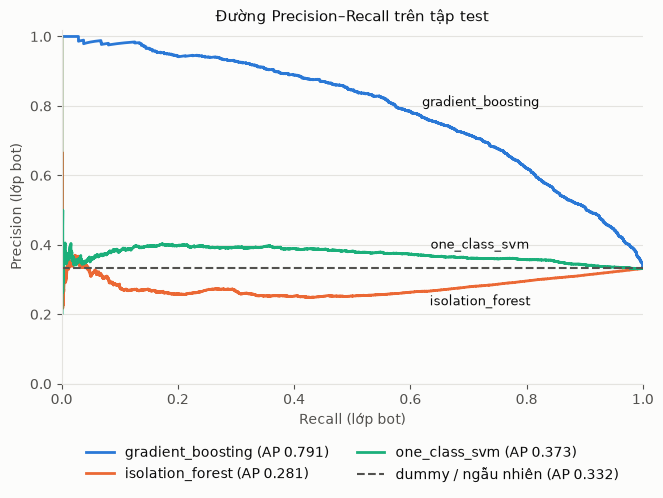

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ap_by_model = metrics.groupby("model")["ap"].first()
label_points = {"gradient_boosting": (0.62, 8), "one_class_svm": (0.72, 7), "isolation_forest": (0.72, -14)}
for name, color in MODEL_COLORS.items():
    precision, recall, _ = precision_recall_curve(y_test, model_scores(name, X_test))
    legend_label = f"{name} (AP {ap_by_model[name]:.3f})"
    ax.plot(recall, precision, color=color, linewidth=2, label=legend_label)
    target_recall, offset = label_points[name]
    point = np.argmin(np.abs(recall - target_recall))
    ax.annotate(name, (recall[point], precision[point]), xytext=(0, offset), textcoords="offset points",
                color=INK, ha="left" if name == "gradient_boosting" else "center", fontsize=9)
ax.axhline(bot_share, color=MUTED, linestyle="--", linewidth=1.5, label=f"dummy / ngẫu nhiên (AP {bot_share:.3f})")
ax.set(title="Đường Precision–Recall trên tập test", xlabel="Recall (lớp bot)", ylabel="Precision (lớp bot)",
       xlim=(0, 1), ylim=(0, 1.02))
ax.grid(axis="y", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
save_figure(fig, "precision_recall_test.png")
plt.show()

Đã lưu: reports/figures/confusion_matrices_test.png


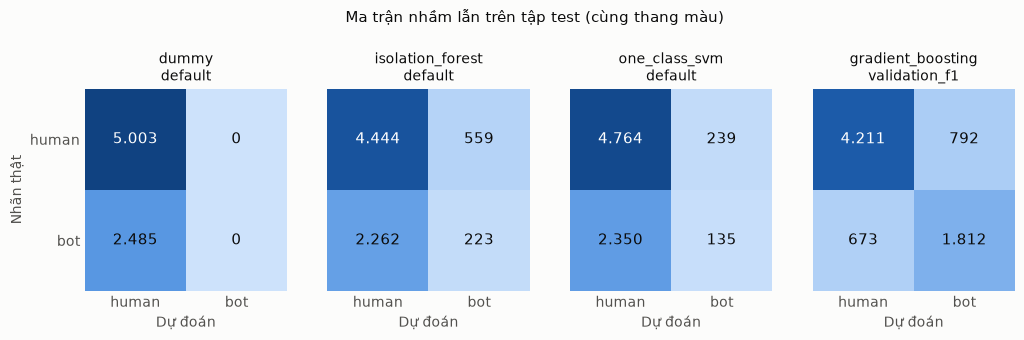

In [7]:
panels = [
    ("dummy", "default"), ("isolation_forest", "default"),
    ("one_class_svm", "default"), ("gradient_boosting", "validation_f1"),
]
BLUE_RAMP = ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"]
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", BLUE_RAMP)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, setting) in zip(axes, panels):
    row = metrics[(metrics["model"] == name) & (metrics["setting"] == setting)].iloc[0]
    matrix = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    ax.imshow(matrix, cmap=cmap, vmin=0, vmax=len(y_test) * (1 - bot_share))
    for (i, j), count in np.ndenumerate(matrix):
        dark_cell = count > 0.5 * len(y_test) * (1 - bot_share)
        ax.text(j, i, f"{count:,}".replace(",", "."), ha="center", va="center",
                color="white" if dark_cell else INK, fontsize=11)
    ax.set_title(f"{name}\n{setting}", fontsize=10)
    ax.set_xticks([0, 1], ["human", "bot"])
    ax.set_yticks([0, 1], ["human", "bot"])
    ax.set_xlabel("Dự đoán")
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel("Nhãn thật")
fig.suptitle("Ma trận nhầm lẫn trên tập test (cùng thang màu)", y=1.06, fontsize=11)
save_figure(fig, "confusion_matrices_test.png")
plt.show()

## Ảnh hưởng của đặc trưng trong Gradient Boosting

- `feature_importances_`: mức giảm impurity trên **train**; không phụ thuộc dữ liệu đánh giá nhưng có thể thiên về đặc trưng nhiều giá trị khác nhau.
- Permutation importance: mức giảm AP trên **validation** khi xáo trộn một đặc trưng (10 lần lặp). Test không được dùng cho phần này.

Importance cho biết mô hình dựa vào đặc trưng nào, không phải quan hệ nhân quả.

,feature,impurity_importance,permutation_ap_drop,permutation_ap_drop_std
0,posting_frequency,0.3777,0.2152,0.0056
1,follower_following_ratio,0.2377,0.1650,0.0061
2,account_age_days,0.2395,0.1618,0.0046
3,bio_length,0.1450,0.0786,0.0037


Đã lưu: reports/figures/feature_importance_gb.png


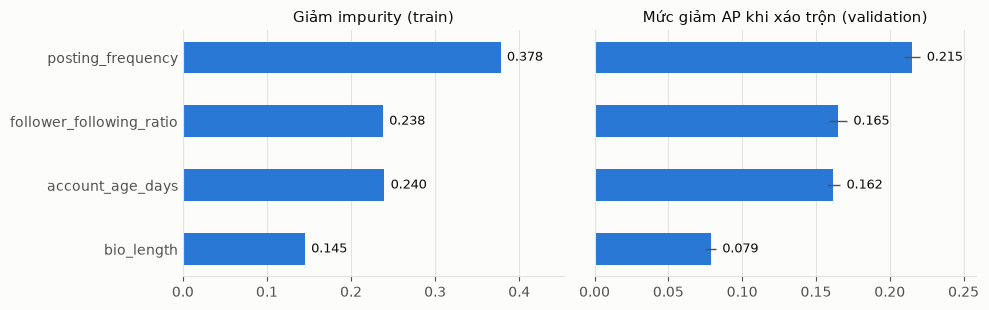

In [8]:
gb_model = bundles["gradient_boosting"]["model"]
permutation = permutation_importance(
    gb_model, feature_matrix(X_val), y_val, scoring="average_precision",
    n_repeats=10, random_state=RANDOM_STATE,
)
importance = pd.DataFrame({
    "feature": list(FEATURE_COLUMNS),
    "impurity_importance": gb_model.named_steps["classifier"].feature_importances_,
    "permutation_ap_drop": permutation.importances_mean,
    "permutation_ap_drop_std": permutation.importances_std,
}).sort_values("permutation_ap_drop", ascending=False, ignore_index=True)
importance.to_csv(REPORTS_DIR / "feature_importance.csv", index=False)
display(importance.round(4))

order = importance.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
panels = (
    ("impurity_importance", None, "Giảm impurity (train)", "{:.3f}"),
    ("permutation_ap_drop", "permutation_ap_drop_std", "Mức giảm AP khi xáo trộn (validation)", "{:.3f}"),
)
for ax, (column, error, title, fmt) in zip(axes, panels):
    bars = ax.barh(order["feature"], order[column], height=0.5, color="#2a78d6",
                   xerr=order[error] if error else None, error_kw={"ecolor": MUTED, "linewidth": 1})
    offset = (order[error].to_numpy() if error else np.zeros(len(order)))
    for bar, extra, value in zip(bars, offset, order[column]):
        ax.text(value + extra + order[column].max() * 0.02, bar.get_y() + bar.get_height() / 2,
                fmt.format(value), va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlim(0, order[column].max() * 1.2)
    ax.grid(axis="x", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
fig.tight_layout()
save_figure(fig, "feature_importance_gb.png")
plt.show()

## Phân tích dự đoán sai của Gradient Boosting trên test

Dùng thiết lập `validation_f1` đã khóa. Bảng so sánh trung vị đặc trưng theo bốn nhóm TN/FP/FN/TP. `verified`, `default_profile` và tỷ lệ bio rỗng chỉ để diễn giải, **không phải đầu vào mô hình**. Phần này chỉ để hiểu giới hạn của mô hình, không dùng để chỉnh lại mô hình. Không hiển thị tên tài khoản hay nội dung bio.

In [9]:
gb_scores = model_scores("gradient_boosting", X_test)
gb_threshold = bundles["gradient_boosting"]["thresholds"]["validation_f1"]
gb_pred = model_predictions("gradient_boosting", X_test, gb_threshold, gb_scores)
outcome = np.select(
    [(y_test == 0) & (gb_pred == 0), (y_test == 0) & (gb_pred == 1), (y_test == 1) & (gb_pred == 0)],
    ["TN (human đúng)", "FP (human bị gắn bot)", "FN (bot bị bỏ sót)"], default="TP (bot đúng)",
)
context = profiles.loc[test.index]
error_rows = []
for group in ("TN (human đúng)", "FP (human bị gắn bot)", "FN (bot bị bỏ sót)", "TP (bot đúng)"):
    mask = outcome == group
    error_rows.append({
        "group": group, "rows": int(mask.sum()), "median_bot_probability": np.median(gb_scores[mask]),
        **X_test[mask].astype("float64").median().to_dict(),
        "verified_share": context.loc[mask, "verified"].eq("True").mean(),
        "default_profile_share": context.loc[mask, "default_profile"].eq("True").mean(),
        "empty_bio_share": X_test.loc[mask, "bio_length"].eq(0).mean(),
    })
error_analysis = pd.DataFrame(error_rows)
error_analysis.to_csv(REPORTS_DIR / "error_analysis.csv", index=False)
display(error_analysis.round(3))

fp_mask, fn_mask = outcome == "FP (human bị gắn bot)", outcome == "FN (bot bị bỏ sót)"
print(f"FP tự tin (xác suất ≥ 0,8): {int((gb_scores[fp_mask] >= 0.8).sum())} / {int(fp_mask.sum())}")
print(f"FN tự tin (xác suất ≤ 0,2): {int((gb_scores[fn_mask] <= 0.2).sum())} / {int(fn_mask.sum())}")

,group,rows,median_bot_probability,follower_following_ratio,posting_frequency,account_age_days,bio_length,verified_share,default_profile_share,empty_bio_share
0,TN (human đúng),4211,0.105,1.909,2.905,3495.0,88.0,0.336,0.283,0.059
1,FP (human bị gắn bot),792,0.568,0.753,0.842,2918.5,20.5,0.078,0.509,0.391
2,FN (bot bị bỏ sót),673,0.183,1.078,2.865,3176.0,76.0,0.062,0.343,0.105
3,TP (bot đúng),1812,0.797,1.000,0.607,2837.5,16.0,0.011,0.727,0.442


FP tự tin (xác suất ≥ 0,8): 95 / 792
FN tự tin (xác suất ≤ 0,2): 372 / 673


## Kết luận và giới hạn

Số liệu lấy từ lần chạy đã lưu trong notebook. Tập test có 7.488 tài khoản, 33,2% là bot; gắn nhãn tất cả là bot cho F1 lớp bot 0,498.

| Mô hình | Thiết lập | Precision | Recall | F1 bot | Macro-F1 | AP | ROC-AUC | Accuracy |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Dummy | mặc định | 0,000 | 0,000 | 0,000 | 0,401 | 0,332 | 0,500 | 0,668 |
| Isolation Forest | mặc định | 0,285 | 0,090 | 0,137 | 0,448 | 0,281 | 0,368 | 0,623 |
| Isolation Forest | ngưỡng validation | 0,332 | 0,998 | 0,498 | 0,249 | 0,281 | 0,368 | 0,332 |
| One-Class SVM | mặc định | 0,361 | 0,054 | 0,094 | 0,440 | 0,373 | 0,564 | 0,654 |
| One-Class SVM | ngưỡng validation | 0,348 | 0,864 | 0,496 | 0,403 | 0,373 | 0,564 | 0,418 |
| Gradient Boosting | mặc định | 0,755 | 0,641 | 0,693 | 0,779 | 0,791 | 0,863 | 0,812 |
| Gradient Boosting | ngưỡng validation | 0,696 | 0,729 | 0,712 | 0,782 | 0,791 | 0,863 | 0,804 |

- **Gradient Boosting tốt nhất rõ rệt** và giữ nguyên hiệu năng từ validation sang test (AP 0,792 → 0,791; F1 0,712 → 0,712), nên không có dấu hiệu chọn cấu hình quá khớp với validation.
- **Hai detector không vượt mốc đơn giản.** Isolation Forest xếp hạng kém hơn ngẫu nhiên (ROC-AUC 0,368). One-Class SVM chỉ nhỉnh hơn một chút (0,564). Ở ngưỡng validation, F1 của hai mô hình (0,498 và 0,496) không hơn mốc tất cả là bot, và Macro-F1 cao nhất của chúng (0,448) vẫn thấp xa so với Gradient Boosting.
- **Dummy cho thấy accuracy không đủ để đánh giá:** accuracy 0,668 dù không phát hiện được bot nào, cao hơn cả hai detector ở mọi thiết lập.
- **Đặc trưng ảnh hưởng nhất:** `posting_frequency` (AP giảm 0,215 khi xáo trộn), rồi `follower_following_ratio` (0,165) và `account_age_days` (0,162), cuối cùng là `bio_length` (0,079). Cả bốn đều có đóng góp.
- **Dự đoán sai có quy luật:** bot bị bỏ sót (FN) có hồ sơ giống người thật, với bio trung vị 76 ký tự và 2,87 bài/ngày, trong khi bot phát hiện đúng có bio 16 ký tự và 0,61 bài/ngày. Người thật bị gắn nhầm (FP) lại có hồ sơ giống bot, với bio 20,5 ký tự và 39,1% bio rỗng. 372/673 FN có xác suất bot ≤ 0,2, tức mô hình sai một cách tự tin; loại này khó khắc phục bằng cách đổi ngưỡng.

**Giới hạn:**

- Chỉ dùng bốn đặc trưng hồ sơ, không có nội dung bài đăng hay mạng lưới tương tác. Các cột có sẵn như `verified` và `default_profile` chưa được dùng; bảng phân tích lỗi cho thấy chúng khác nhau giữa các nhóm, nhưng chưa kiểm chứng việc thêm chúng có cải thiện mô hình hay không.
- `posting_frequency` là trung bình cả vòng đời và `account_age_days` là giá trị lịch sử của nguồn, không phản ánh hoạt động gần đây.
- Dữ liệu là một bộ đã gán nhãn sẵn và được chia ngẫu nhiên, nên kết quả không chứng minh mô hình hoạt động tốt với tài khoản mới hoặc bot đổi hành vi theo thời gian.
- Kết quả là ước lượng điểm trên một lần chia, chưa có khoảng tin cậy.
- Với precision khoảng 0,70, cứ 10 tài khoản bị gắn bot thì khoảng 3 là người thật. Điểm số chỉ phản ánh mức giống nhãn `bot` của dữ liệu, không đủ để kết luận tài khoản giả mạo hay lừa đảo.